# 02 · Results analysis

Walk-forward results for every model. Each model is retrained on an expanding window and scored on
the following year, six times (Sep 2020 – Oct 2026, 1,512 trading days per stock). The strategy goes
long the next day when the forecast is positive and holds cash otherwise, paying 0.12% per side.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import load_config, resolve_path

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
cfg = load_config()

In [2]:
import yaml
from scipy.stats import wilcoxon

m = pd.read_csv(resolve_path("results/metrics.csv"), dtype={"fold": str})
allf = m[m["fold"] == "all"]
order = ["random_walk", "persistence", "majority", "arima", "xgboost", "lstm", "transformer",
         "xgboost+news", "lstm+news", "transformer+news"]
order = [o for o in order if o in set(allf["model"])]
print(sorted(allf["model"].unique()))

['arima', 'lstm', 'lstm+news', 'majority', 'persistence', 'random_walk', 'transformer', 'xgboost', 'xgboost+news']


## Averages across the 10 stocks

In [3]:
cols = {"dir_acc": "dir acc %", "p_vs_50": "p vs 50%", "mape": "MAPE %", "strat_sharpe": "Sharpe (net)",
        "strat_cagr": "CAGR", "strat_max_dd": "max DD", "exposure": "time in mkt"}
summary = allf.groupby("model")[list(cols)].mean().rename(columns=cols).reindex(order)
bh = allf.groupby("ticker")[["bh_sharpe", "bh_cagr", "bh_max_dd"]].first().mean()
summary.loc["buy & hold"] = [np.nan, np.nan, np.nan, bh["bh_sharpe"], bh["bh_cagr"], bh["bh_max_dd"], 1.0]
summary

,dir acc %,p vs 50%,MAPE %,Sharpe (net),CAGR,max DD,time in mkt
model,,,,,,,
random_walk,NaN,NaN,1.060,NaN,0.000,0.000,0.000
persistence,49.451,0.610,1.532,-0.443,-0.077,-0.557,0.509
majority,49.378,0.652,1.062,0.346,0.040,-0.285,0.683
arima,50.430,0.398,1.062,0.342,0.061,-0.398,0.864
xgboost,50.271,0.424,1.068,0.324,0.052,-0.380,0.851
lstm,51.025,0.286,1.064,0.379,0.061,-0.343,0.726
transformer,50.575,0.392,1.064,0.244,0.028,-0.357,0.650
xgboost+news,50.807,0.362,1.068,0.469,0.089,-0.356,0.894
lstm+news,50.179,0.434,1.067,0.312,0.044,-0.355,0.703


## How often does a model beat the simple alternatives?

Per stock: is direction accuracy significantly above 50% (one-sided binomial p < 0.05), and does the
strategy beat buy & hold on Sharpe and on CAGR? With ~10 models × 10 stocks, a few p < 0.05 results
are expected by chance alone.

In [4]:
wins = allf.assign(
    significant=allf["p_vs_50"] < 0.05,
    sharpe_beats_bh=allf["strat_sharpe"] > allf["bh_sharpe"],
    cagr_beats_bh=allf["strat_cagr"] > allf["bh_cagr"],
).groupby("model")[["significant", "sharpe_beats_bh", "cagr_beats_bh"]].sum().reindex(order)
wins.columns = ["p<0.05 (of 10)", "Sharpe > B&H (of 10)", "CAGR > B&H (of 10)"]
wins

,p<0.05 (of 10),Sharpe > B&H (of 10),CAGR > B&H (of 10)
model,,,
random_walk,0,0,1
persistence,0,0,0
majority,0,0,0
arima,0,1,1
xgboost,0,0,0
lstm,2,0,0
transformer,2,0,0
xgboost+news,3,0,0
lstm+news,1,1,1


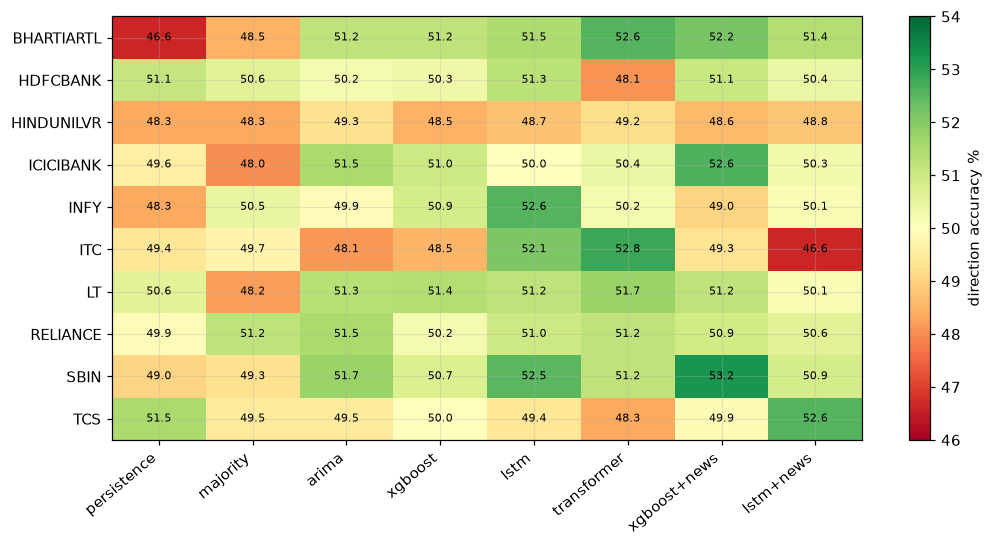

In [5]:
pivot = allf.pivot(index="ticker", columns="model", values="dir_acc")[[o for o in order if o != "random_walk"]]
fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(pivot, cmap="RdYlGn", vmin=46, vmax=54, aspect="auto")
ax.set_xticks(range(pivot.shape[1]), pivot.columns, rotation=40, ha="right")
ax.set_yticks(range(pivot.shape[0]), pivot.index)
for (i, j), v in np.ndenumerate(pivot.to_numpy()):
    ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, label="direction accuracy %")
plt.show()

## Is accuracy stable across folds?

If a model had a real edge it should show up in most years, not just one.

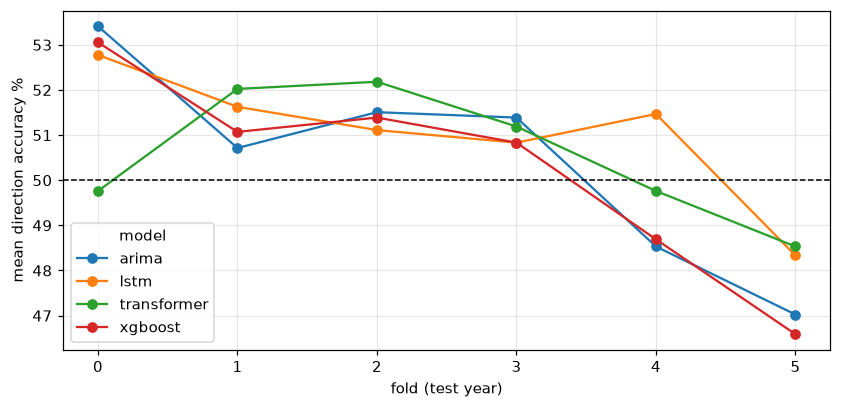

In [6]:
folds = m[(m["fold"] != "all") & m["model"].isin(["xgboost", "lstm", "transformer", "arima"])]
ax = folds.groupby(["fold", "model"])["dir_acc"].mean().unstack().plot(marker="o", figsize=(9, 4))
ax.axhline(50, c="k", ls="--", lw=1)
ax.set_xlabel("fold (test year)")
ax.set_ylabel("mean direction accuracy %")
plt.show()

## Equity curves for one stock

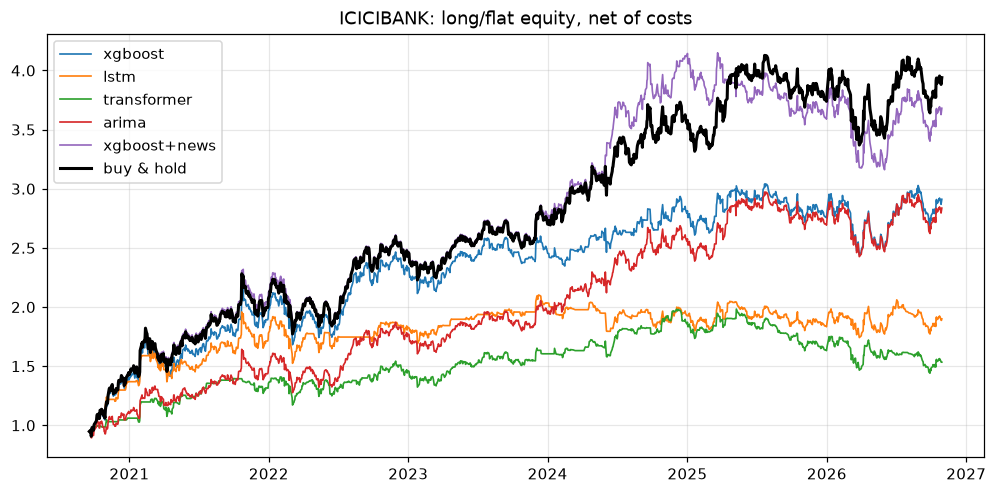

In [7]:
from src.evaluation.metrics import strategy_returns

ticker = "ICICIBANK"
preds = pd.read_parquet(resolve_path(f"results/predictions/{ticker}.parquet")).sort_values("date")
fig, ax = plt.subplots(figsize=(11, 5))
for name in ["xgboost", "lstm", "transformer", "arima", "xgboost+news"]:
    g = preds[preds["model"] == name]
    if g.empty:
        continue
    daily, _ = strategy_returns(g["actual"].to_numpy(), g["pred"].to_numpy(), 0.0, cfg["strategy"]["cost_per_side"])
    ax.plot(g["date"], np.cumprod(1 + daily), lw=1.1, label=name)
y = g["actual"].to_numpy()
bh, _ = strategy_returns(y, np.ones_like(y), 0.0, cfg["strategy"]["cost_per_side"])
ax.plot(g["date"], np.cumprod(1 + bh), c="k", lw=2, label="buy & hold")
ax.set_title(f"{ticker}: long/flat equity, net of costs")
ax.legend()
plt.show()

## Does FinBERT news sentiment help? (ablation)

Same models, same folds, with and without the four daily news features. The table shows the change
per stock; the Wilcoxon signed-rank test asks whether the change is consistently positive across the
10 stocks.

In [8]:
rows = []
for base in ["xgboost", "lstm", "transformer"]:
    a = allf[allf["model"] == base].set_index("ticker")
    b = allf[allf["model"] == base + "+news"].set_index("ticker")
    if b.empty:
        continue
    for metric in ["dir_acc", "strat_sharpe"]:
        delta = (b[metric] - a[metric]).dropna()
        p = wilcoxon(delta, alternative="greater").pvalue if len(delta) > 5 else np.nan
        rows.append({"model": base, "metric": metric, "mean change": delta.mean(), "stocks improved": (delta > 0).sum(),
                     "of": len(delta), "Wilcoxon p (improves)": p})
ablation = pd.DataFrame(rows)
ablation

,model,metric,mean change,stocks improved,of,Wilcoxon p (improves)
0,xgboost,dir_acc,0.536,7,10,0.085
1,xgboost,strat_sharpe,0.144,7,10,0.065
2,lstm,dir_acc,-0.847,3,10,0.924
3,lstm,strat_sharpe,-0.067,3,10,0.839


## Hyperparameter tuning

Optuna searched each model on the first fold's validation block only (it ends before the first test
day). The objective is validation MSE / Var(y), so 1.0 means "no better than predicting the mean".

In [9]:
tuned = yaml.safe_load(resolve_path("configs/tuned.yaml").read_text())
pd.DataFrame(tuned["studies"]).T[["trials", "hand_set_value", "best_value"]]

,trials,hand_set_value,best_value
xgboost,60,0.996,0.977
lstm,20,0.999,0.997
transformer,15,1.012,0.994


## Is anything here predictable at high accuracy?

Next-day direction sits at ~50%, so I checked whether an easier question does better. Same
walk-forward folds (embargo ≥ the horizon), an XGBoost classifier, and the trivial baseline of always
predicting the training set's most common class:

* **1-day direction**: the target used everywhere else.
* **20-day direction**: will the stock be higher in a month?
* **5-day volatility regime**: will next week's volatility be above its trailing one-year median?

In [10]:
from xgboost import XGBClassifier

from src.data.loader import load_ohlcv
from src.evaluation.splits import walk_forward_folds
from src.features.build import FEATURE_COLUMNS, build_feature_frame

rows = []
for ticker in ["TCS.NS", "HDFCBANK.NS", "RELIANCE.NS", "ITC.NS"]:
    f = build_feature_frame(load_ohlcv(ticker, resolve_path("data/raw"), "15y", "1d"))
    r = f["ret_1"]
    rv_fwd5 = pd.concat([r.shift(-k) for k in range(1, 6)], axis=1).std(axis=1)
    threshold = f["volatility"].rolling(252, min_periods=120).median()  # past data only
    targets = {
        "1-day direction": (f["target"] > 0, 1),
        "20-day direction": (np.log(f["close"].shift(-20) / f["close"]) > 0, 20),
        "5-day vol regime": (rv_fwd5 > threshold, 5),
    }
    for name, (label, horizon) in targets.items():
        d = pd.concat([f[FEATURE_COLUMNS], label.rename("y"), threshold.rename("thr"),
                       rv_fwd5.rename("rv"), f["close"].shift(-horizon).rename("fwd")], axis=1).dropna()
        X, y = d[FEATURE_COLUMNS].to_numpy(), d["y"].astype(int).to_numpy()
        hits = base = n = 0
        for fold in walk_forward_folds(len(d), 6, 252, 0.15, embargo=max(5, horizon)):
            clf = XGBClassifier(n_estimators=400, learning_rate=0.03, max_depth=3, subsample=0.8,
                                colsample_bytree=0.8, early_stopping_rounds=40, eval_metric="logloss")
            clf.fit(X[fold.train], y[fold.train], eval_set=[(X[fold.val], y[fold.val])], verbose=False)
            hits += (clf.predict(X[fold.test]) == y[fold.test]).sum()
            base += (y[fold.test] == int(y[fold.train].mean() >= 0.5)).sum()
            n += len(fold.test)
        rows.append({"ticker": ticker, "target": name, "model %": hits / n * 100, "always-majority %": base / n * 100})

probe = pd.DataFrame(rows)
probe.groupby("target")[["model %", "always-majority %"]].mean()

,model %,always-majority %
target,,
1-day direction,50.265,50.182
20-day direction,52.282,51.769
5-day vol regime,61.938,62.583


Even the easier targets stay within a couple of points of the trivial baseline. The volatility
regime looks like 60%+ but so does always guessing the usual regime. A model that claimed 80%
here would have to be leaking future data.

## Conclusions

* No model shows a reliable edge on next-day direction. Mean accuracies are 49–51%, and the handful
  of stock/model pairs with p < 0.05 are scattered across stocks and models rather than consistent,
  which is what multiple testing produces.
* Buy & hold is hard to beat in a rising market: averaged over the 10 stocks it returned 14% a year
  with a Sharpe of 0.65, while the best long/flat strategy (XGBoost with news) returned about 9% with
  a Sharpe of 0.47. Strategies beat buy & hold on return for at most one stock per model.
* News features help XGBoost on 7 of 10 stocks (Wilcoxon p = 0.07–0.09, suggestive but not significant)
  and hurt the LSTM. Coverage is thin in early years, so this is a weak test of news as a signal.
* Tuning lowered validation error, but the objective stays close to 1.0 (almost all next-day variance
  is unexplained) and tuned XGBoost did slightly worse on the test years than the hand-set one did in
  the first backtest, a reminder that validation gains on noisy targets rarely carry over.